# Credit Card Fraud Detection

This notebook explores the `card_transdata.csv` dataset to understand how fraudulent transactions differ from legitimate ones, then compares a naive "never fraud" baseline with a **K-Nearest Neighbors (KNN)** classifier built with scikit-learn.

**Dataset columns**

| Column | Type | Description |
|---|---|---|
| `distance_from_home` | continuous | Distance from home where the transaction happened |
| `distance_from_last_transaction` | continuous | Distance from where the last transaction happened |
| `ratio_to_median_purchase_price` | continuous | Purchase price divided by the cardholder's median purchase price |
| `repeat_retailer` | binary | Transaction happened at a retailer used before |
| `used_chip` | binary | Transaction used the card's chip |
| `used_pin_number` | binary | Transaction used a PIN number |
| `online_order` | binary | Transaction was an online order |
| `fraud` | binary (target) | 1 = fraudulent, 0 = legitimate |

**Outline**
1. Setup and data loading
2. Data quality checks
3. Exploratory analysis: target balance, purchase-price ratio distribution, scatter plots, binary features, fraud breakdown for every variable, correlations
4. Modeling: 80/20 split, "never fraud" baseline, KNN (k = 3), model comparison
5. Conclusions

## 1. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# Consistent colors for the two classes throughout the notebook
CLASS_COLORS = {0: "#4C72B0", 1: "#DD5555"}
CLASS_NAMES = {0: "Legitimate", 1: "Fraud"}
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("card_transdata.csv")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 999   Columns: 8


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.878,0.311,1.946,1.000,1.000,0.000,0.000,0
1,10.830,0.176,1.294,1.000,NaN,0.000,0.000,0
2,5.091,NaN,0.428,1.000,0.000,0.000,1.000,0
3,2.248,5.600,0.363,1.000,1.000,0.000,1.000,0
4,44.191,0.566,2.223,1.000,1.000,0.000,1.000,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


## 2. Data quality checks

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
print(f"Duplicate rows: {df.duplicated().sum()}")
quality

Duplicate rows: 0


,dtype,missing,missing_%,unique_values
distance_from_home,float64,0,0.000,999
distance_from_last_transaction,float64,3,0.300,996
ratio_to_median_purchase_price,float64,2,0.200,997
repeat_retailer,float64,7,0.700,2
used_chip,float64,4,0.400,2
used_pin_number,float64,2,0.200,2
online_order,float64,4,0.400,2
fraud,int64,0,0.000,2


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
distance_from_home,999.000,26.877,63.900,0.104,3.991,10.340,25.394,965.911
distance_from_last_transaction,996.000,5.437,35.668,0.001,0.306,0.959,3.137,990.070
ratio_to_median_purchase_price,997.000,1.655,2.351,0.017,0.468,0.956,1.922,36.074
repeat_retailer,992.000,0.892,0.310,0.000,1.000,1.000,1.000,1.000
used_chip,995.000,0.314,0.464,0.000,0.000,0.000,1.000,1.000
used_pin_number,997.000,0.117,0.322,0.000,0.000,0.000,0.000,1.000
online_order,995.000,0.673,0.469,0.000,0.000,1.000,1.000,1.000
fraud,999.000,0.079,0.270,0.000,0.000,0.000,0.000,1.000


**Observations**
- A handful of values are missing in most feature columns (less than 1% per column). Rather than dropping rows, these will be **imputed** inside the modeling pipeline (median value, learned from the training data only).
- The three distance/price features are heavily **right-skewed**: their maximum values are far larger than their 75th percentiles.

In [6]:
TARGET = "fraud"
continuous_cols = ["distance_from_home", "distance_from_last_transaction", "ratio_to_median_purchase_price"]
binary_cols = ["repeat_retailer", "used_chip", "used_pin_number", "online_order"]
feature_cols = continuous_cols + binary_cols

## 3. Exploratory data analysis

### 3.1 Target variable: how common is fraud?

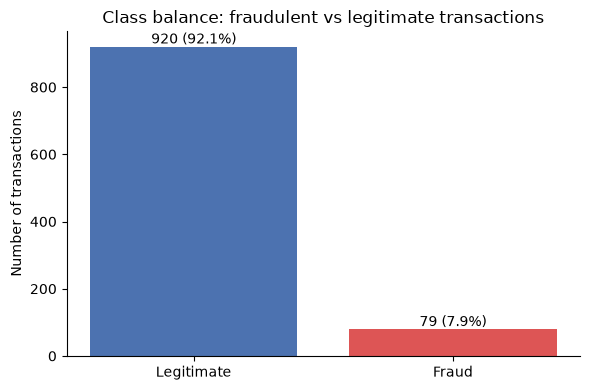

In [7]:
counts = df[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([CLASS_NAMES[i] for i in counts.index], counts.values,
              color=[CLASS_COLORS[i] for i in counts.index])
for bar, c, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{c} ({p:.1f}%)",
            ha="center", va="bottom")
ax.set_title("Class balance: fraudulent vs legitimate transactions")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

The dataset is **imbalanced**: only about 8% of transactions are fraudulent. A model that always predicts "legitimate" would already be about 92% accurate, so accuracy alone is a misleading metric. Section 4 shows this directly.

### 3.2 Distribution of `ratio_to_median_purchase_price`

count   997.000
mean      1.655
std       2.351
min       0.017
25%       0.468
50%       0.956
75%       1.922
max      36.074
Name: ratio_to_median_purchase_price, dtype: float64


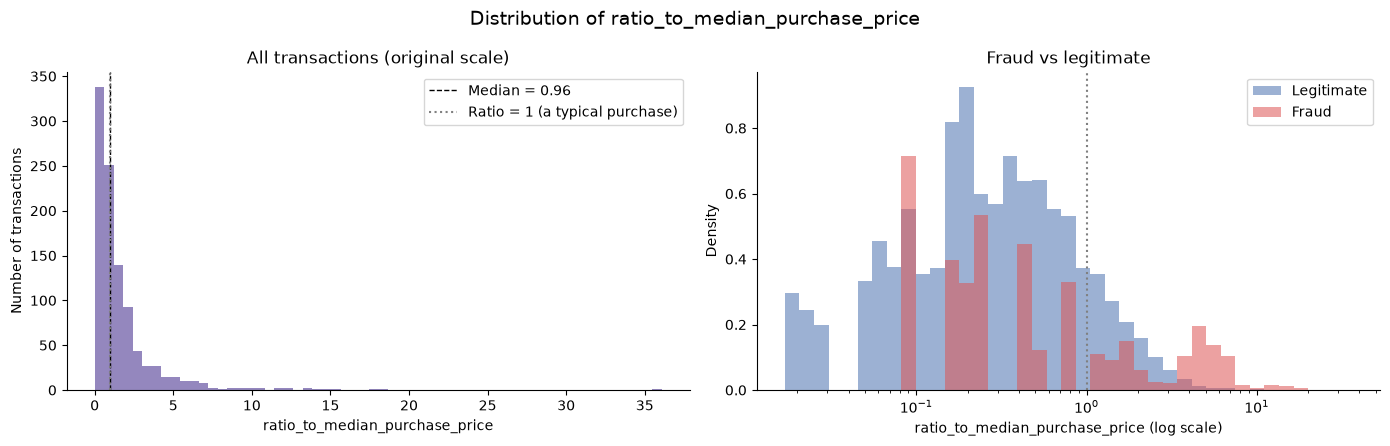

In [8]:
col = "ratio_to_median_purchase_price"
ratio = df[col].dropna()
print(ratio.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: overall distribution on the original scale
axes[0].hist(ratio, bins=60, color="#8172B3", alpha=0.85)
axes[0].axvline(ratio.median(), color="black", ls="--", lw=1, label=f"Median = {ratio.median():.2f}")
axes[0].axvline(1, color="gray", ls=":", lw=1.5, label="Ratio = 1 (a typical purchase)")
axes[0].set_xlabel(col)
axes[0].set_ylabel("Number of transactions")
axes[0].set_title("All transactions (original scale)")
axes[0].legend()

# Right: fraud vs legitimate on a log x-axis, which spreads out the long right tail
bins = np.logspace(np.log10(ratio.min()), np.log10(ratio.max()), 40)
for k in (0, 1):
    axes[1].hist(df.loc[df[TARGET] == k, col].dropna(), bins=bins, density=True, alpha=0.55,
                 color=CLASS_COLORS[k], label=CLASS_NAMES[k])
axes[1].axvline(1, color="gray", ls=":", lw=1.5)
axes[1].set_xscale("log")
axes[1].set_xlabel(f"{col} (log scale)")
axes[1].set_ylabel("Density")
axes[1].set_title("Fraud vs legitimate")
axes[1].legend()

fig.suptitle("Distribution of ratio_to_median_purchase_price", fontsize=14)
plt.tight_layout()
plt.show()

Most purchases sit near or below the cardholder's usual amount (ratio around 1), with a long tail of unusually large purchases. The right-hand panel shows that **legitimate purchases are mostly below a ratio of 1, while a large share of fraudulent purchases sit in the tail**, at several times the cardholder's median purchase. Not all fraud is large, though: some fraudulent purchases are ordinary-sized, so this feature alone can't catch every case.

### 3.3 Scatter plots: purchase-price ratio vs distance

In [9]:
def ratio_scatter(x_col):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    # Plot legitimate first so the rarer fraud points are drawn on top
    for k in (0, 1):
        sub = df[df[TARGET] == k]
        ax.scatter(sub[x_col], sub["ratio_to_median_purchase_price"],
                   s=14 if k == 0 else 26, alpha=0.4 if k == 0 else 0.85,
                   color=CLASS_COLORS[k], label=f"{CLASS_NAMES[k]} (n={len(sub)})")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{x_col} (log scale)")
    ax.set_ylabel("ratio_to_median_purchase_price (log scale)")
    ax.set_title(f"ratio_to_median_purchase_price vs {x_col}")
    ax.legend()
    plt.tight_layout()
    plt.show()

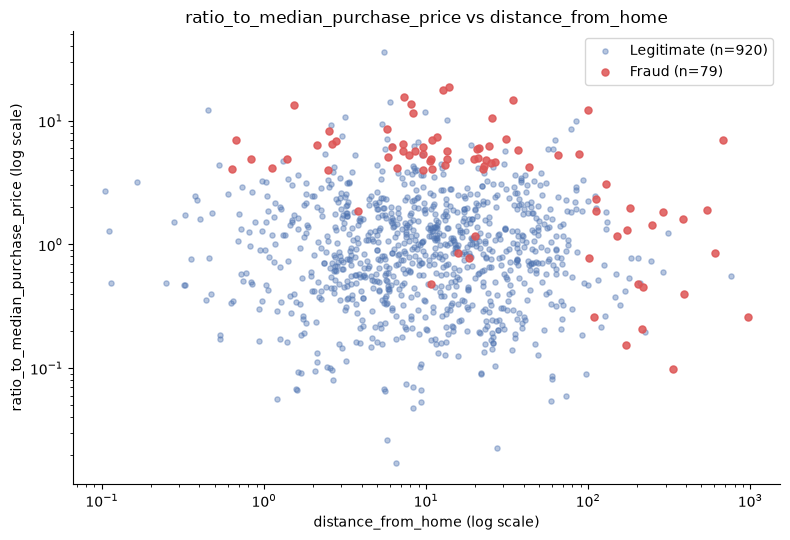

In [10]:
ratio_scatter("distance_from_home")

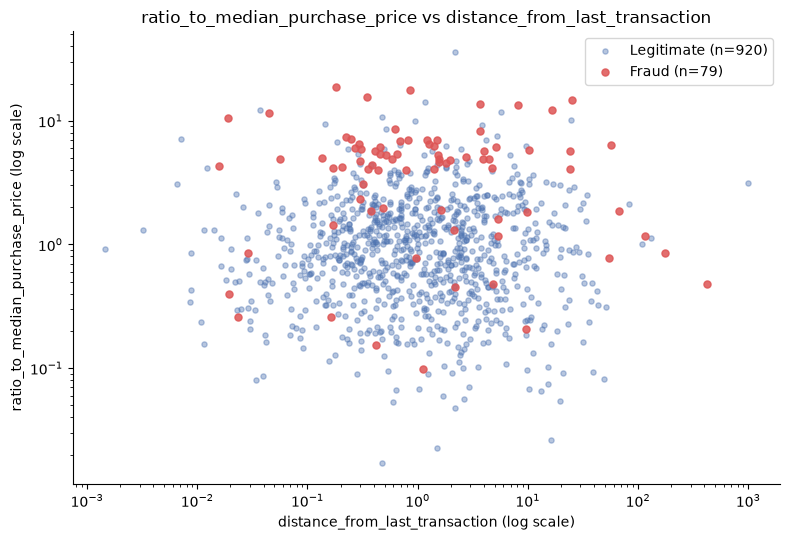

In [11]:
ratio_scatter("distance_from_last_transaction")

Both axes use a log scale because the raw values are so skewed that most points would otherwise be squashed into one corner.

- **vs `distance_from_home`**: fraud shows up in two regions. Most fraud points sit in the **upper part** of the plot (unusually large purchases) at almost any distance. A second group sits at the **far right** (roughly 100+ units from home), where even normal-sized purchases are often fraudulent. Together, the two features explain cases that either one alone would miss.
- **vs `distance_from_last_transaction`**: the vertical separation (purchase size) is still clear, but fraud is spread across the whole x-axis, so distance from the last transaction adds less information than distance from home.

### 3.4 Binary features: one chart per feature

Each binary flag gets its own chart. The left panel shows what share of legitimate and fraudulent transactions have the flag off (0) or on (1). The right panel shows the fraud rate in each group.

In [12]:
# Summary table of fraud rate when each flag is 0 vs 1
summary = []
for col in binary_cols:
    for val in (0, 1):
        sub = df[df[col] == val]
        summary.append({"feature": col, "value": val, "transactions": len(sub),
                        "fraud_cases": int(sub[TARGET].sum()),
                        "fraud_rate_%": sub[TARGET].mean() * 100})
binary_summary = pd.DataFrame(summary)
binary_summary

,feature,value,transactions,fraud_cases,fraud_rate_%
0,repeat_retailer,0,107,6,5.607
1,repeat_retailer,1,885,72,8.136
2,used_chip,0,683,65,9.517
3,used_chip,1,312,13,4.167
4,used_pin_number,0,880,79,8.977
5,used_pin_number,1,117,0,0.000
6,online_order,0,325,2,0.615
7,online_order,1,670,76,11.343


In [13]:
overall_rate = df[TARGET].mean() * 100

def plot_breakdown(groups, title, xlabel):
    """Two-panel bar chart for one variable.

    groups: a Series of category labels (one per transaction, NaN rows are skipped).
    Left: % of each class falling in each category. Right: fraud rate in each category.
    Returns the fraud rate per category.
    """
    data = pd.DataFrame({"group": groups, TARGET: df[TARGET]}).dropna()
    within_class = pd.crosstab(data["group"], data[TARGET], normalize="columns") * 100
    rate = data.groupby("group", observed=True)[TARGET].mean() * 100
    n = data["group"].value_counts().reindex(rate.index)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
    x = np.arange(len(within_class))
    w = 0.38
    for offset, k in zip((-w / 2, w / 2), (0, 1)):
        bars = axes[0].bar(x + offset, within_class[k].values, w, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
        for b, v in zip(bars, within_class[k].values):
            axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.0f}%",
                         ha="center", va="bottom", fontsize=9)
    axes[0].set_xticks(x, within_class.index.astype(str))
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("% of transactions in class")
    axes[0].set_title("Share of each class in each group")
    axes[0].legend()

    bars = axes[1].bar(x, rate.values, color="#8172B3")
    for b, r, cnt in zip(bars, rate.values, n.values):
        axes[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{r:.1f}%\n(n={cnt})",
                     ha="center", va="bottom", fontsize=9)
    axes[1].axhline(overall_rate, color="gray", ls="--", lw=1, label=f"Overall fraud rate {overall_rate:.1f}%")
    axes[1].set_xticks(x, rate.index.astype(str))
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel("Fraud rate (%)")
    axes[1].set_ylim(0, max(rate.max() * 1.25, overall_rate * 1.5))
    axes[1].set_title("Fraud rate in each group")
    axes[1].legend(loc="upper left")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return rate

def binary_groups(col):
    return df[col].map({0: "No (0)", 1: "Yes (1)"})

fraud_rate_by_group = {}

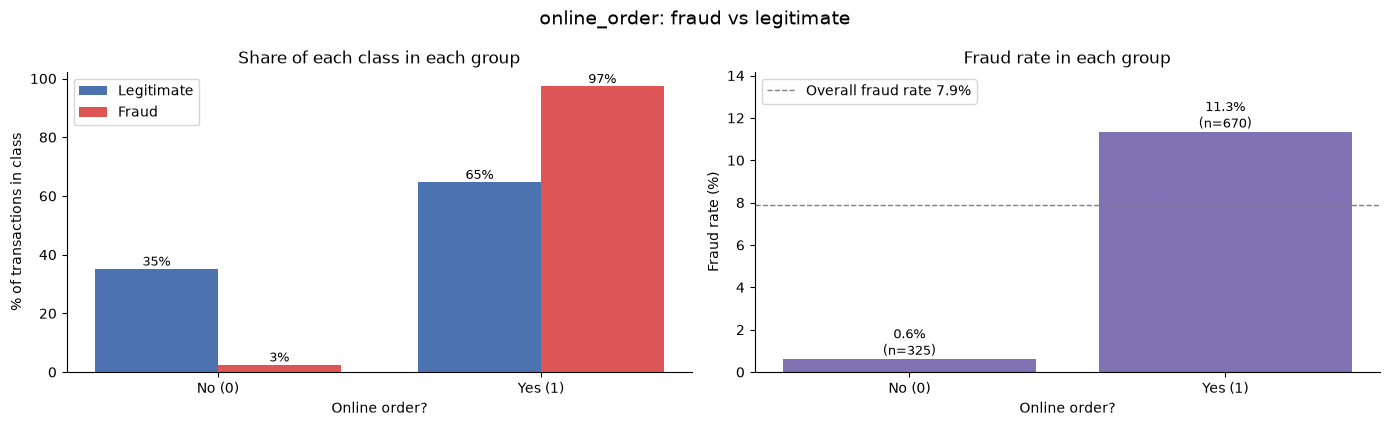

In [14]:
fraud_rate_by_group["online_order"] = plot_breakdown(
    binary_groups("online_order"), "online_order: fraud vs legitimate", "Online order?")

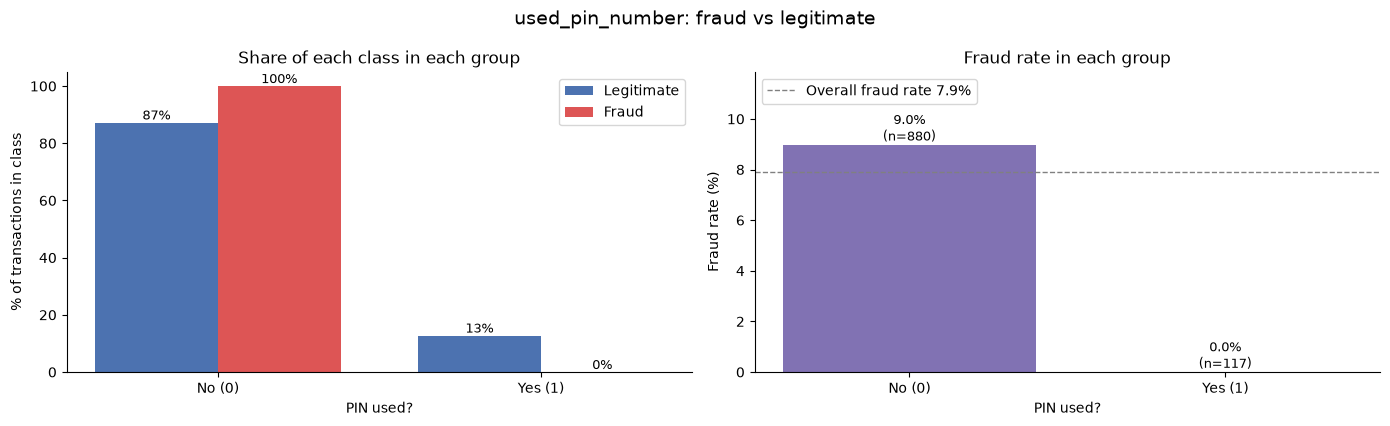

In [15]:
fraud_rate_by_group["used_pin_number"] = plot_breakdown(
    binary_groups("used_pin_number"), "used_pin_number: fraud vs legitimate", "PIN used?")

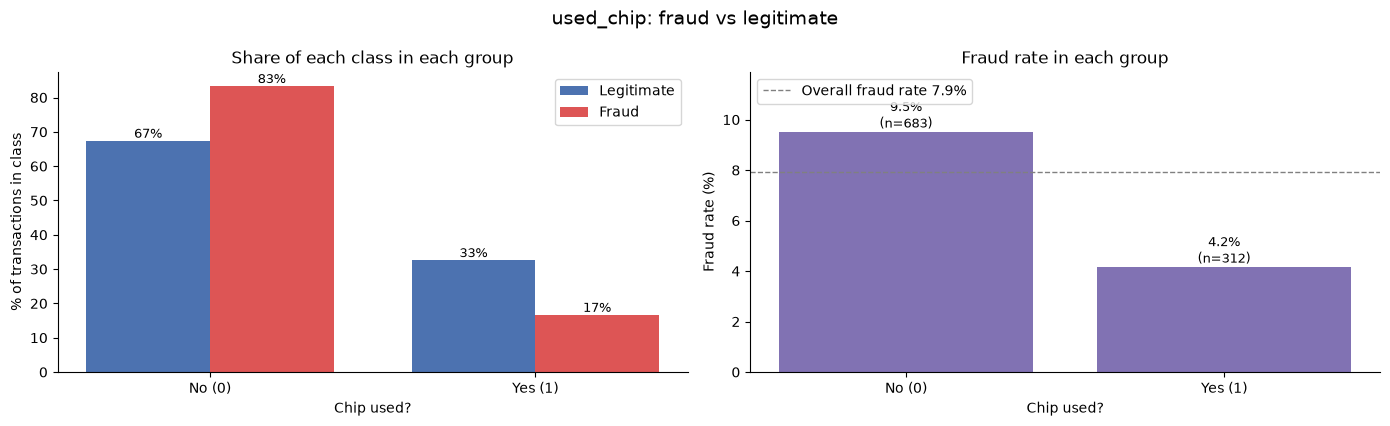

In [16]:
fraud_rate_by_group["used_chip"] = plot_breakdown(
    binary_groups("used_chip"), "used_chip: fraud vs legitimate", "Chip used?")

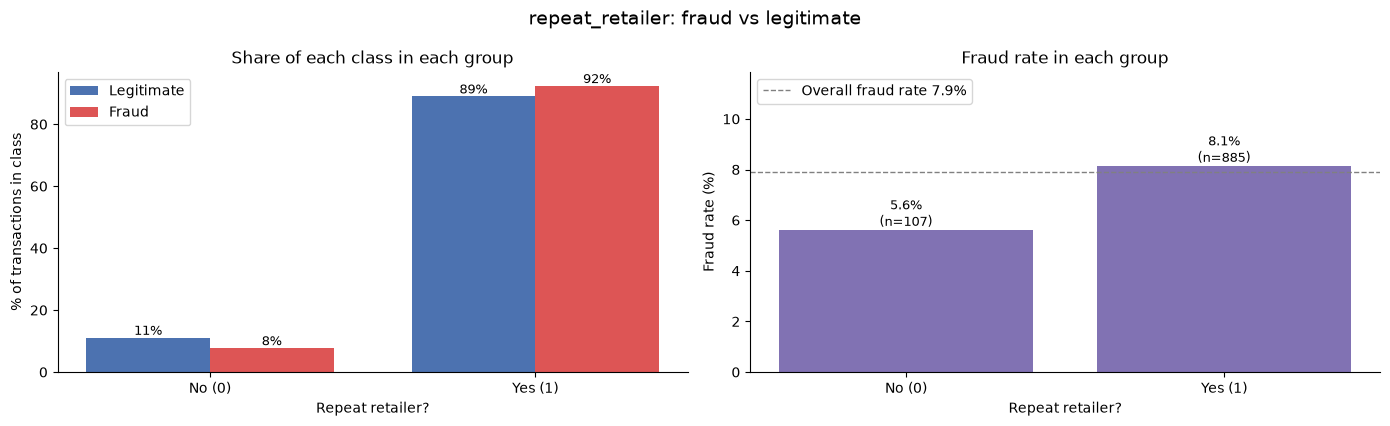

In [17]:
fraud_rate_by_group["repeat_retailer"] = plot_breakdown(
    binary_groups("repeat_retailer"), "repeat_retailer: fraud vs legitimate", "Repeat retailer?")

**Observations**
- **`online_order`**: almost all fraud in this data happens online, while a large share of legitimate transactions are in person. This is one of the strongest signals.
- **`used_pin_number`**: none of the transactions that used a PIN were fraudulent. A PIN is strong evidence that the real cardholder was present.
- **`used_chip`**: chip transactions have a lower fraud rate than non-chip transactions.
- **`repeat_retailer`**: the two groups look similar, so this flag carries little information on its own.

### 3.5 Continuous features: fraud breakdown by range

To compare the continuous variables with the binary ones, each continuous variable is split into five equal-sized groups (quintiles, from lowest 20% to highest 20%) and shown in the same two-panel format.

In [18]:
def quintile_groups(col):
    binned = pd.qcut(df[col], q=5)
    labels = [f"Q{i + 1}\n{iv.left:.2f}-{iv.right:.2f}" for i, iv in enumerate(binned.cat.categories)]
    return binned.cat.rename_categories(labels)

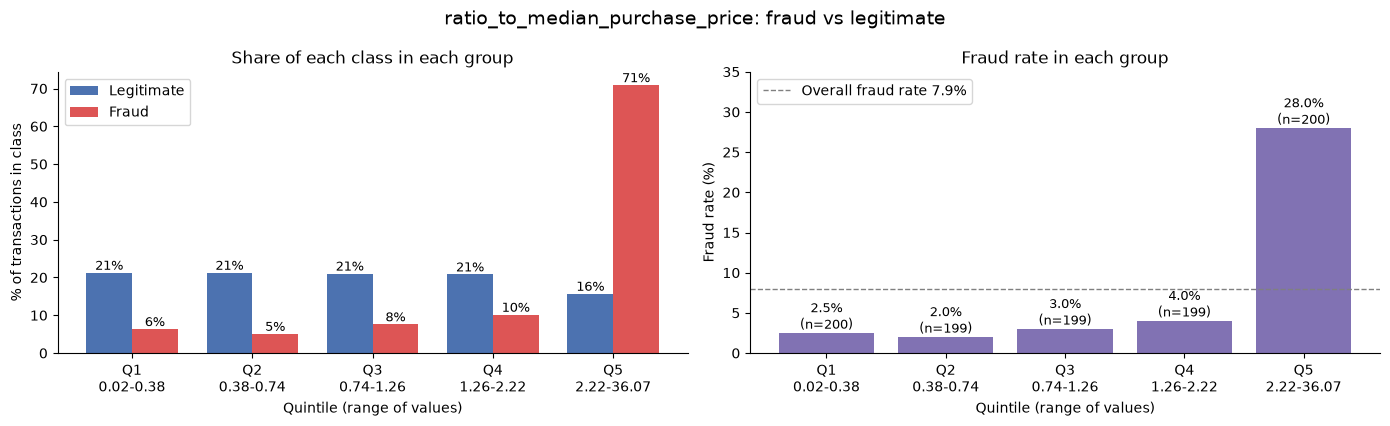

In [19]:
fraud_rate_by_group["ratio_to_median_purchase_price"] = plot_breakdown(
    quintile_groups("ratio_to_median_purchase_price"),
    "ratio_to_median_purchase_price: fraud vs legitimate", "Quintile (range of values)")

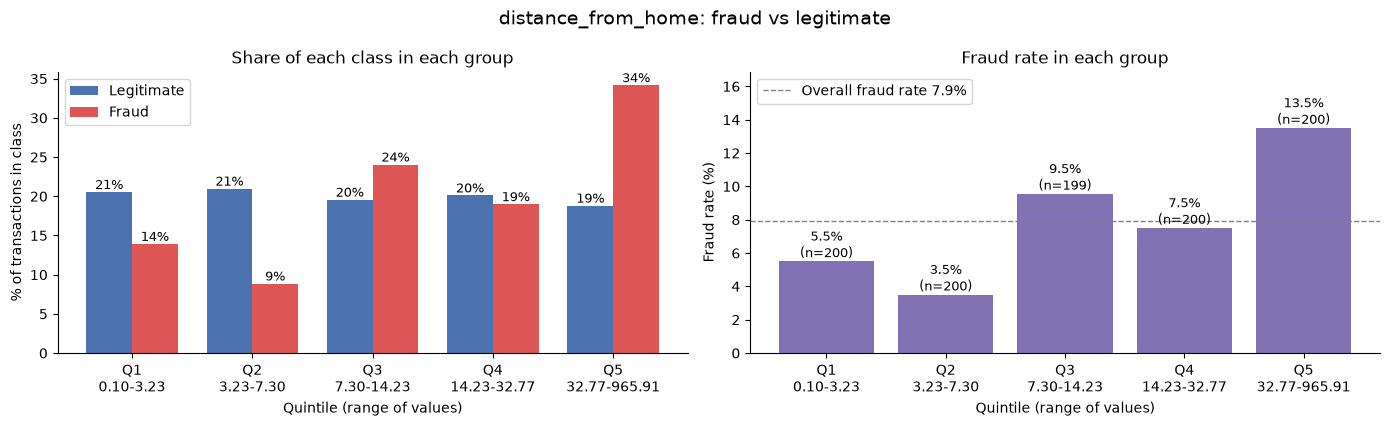

In [20]:
fraud_rate_by_group["distance_from_home"] = plot_breakdown(
    quintile_groups("distance_from_home"),
    "distance_from_home: fraud vs legitimate", "Quintile (range of values)")

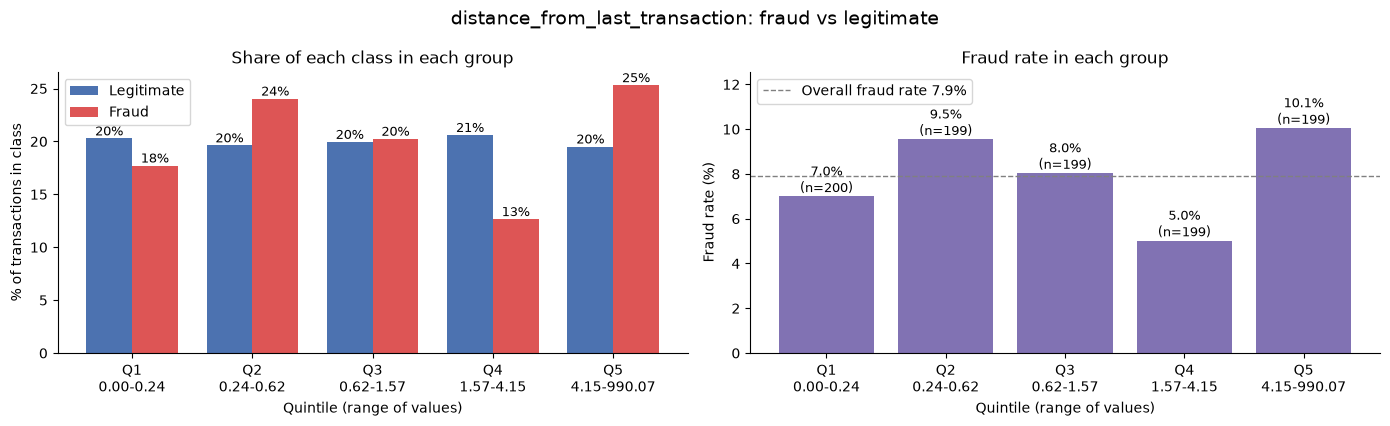

In [21]:
fraud_rate_by_group["distance_from_last_transaction"] = plot_breakdown(
    quintile_groups("distance_from_last_transaction"),
    "distance_from_last_transaction: fraud vs legitimate", "Quintile (range of values)")

**Observations**
- **`ratio_to_median_purchase_price`**: fraud is heavily concentrated in the top quintile (the largest purchases relative to the cardholder's norm).
- **`distance_from_home`**: the fraud rate rises in the higher quintiles, especially the top one.
- **`distance_from_last_transaction`**: the fraud rate changes less across quintiles, so this is a weaker signal.

### 3.6 Which variables matter most?

A simple way to rank the variables from the charts above: for each variable, take the **spread in fraud rate** between its highest-fraud group and its lowest-fraud group. A variable whose groups have very different fraud rates is more useful for telling fraud apart from legitimate transactions.

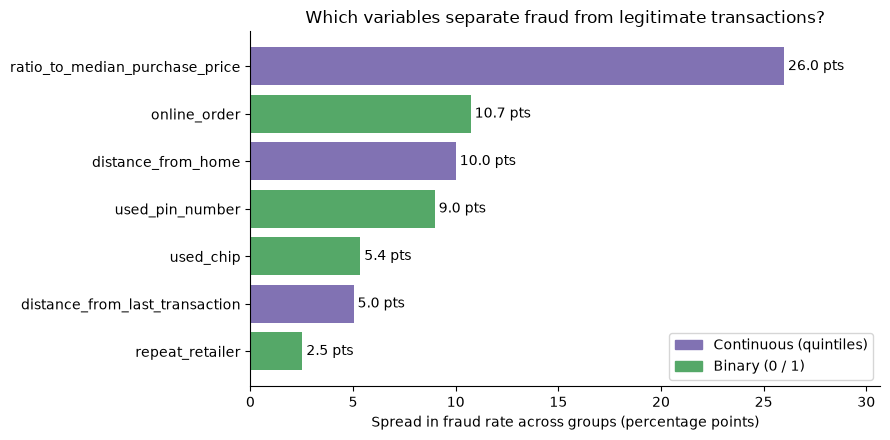

In [22]:
spread = pd.Series({col: rate.max() - rate.min() for col, rate in fraud_rate_by_group.items()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#8172B3" if c in continuous_cols else "#55A868" for c in spread.index]
bars = ax.barh(spread.index, spread.values, color=colors)
for b, v in zip(bars, spread.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {v:.1f} pts", va="center")
ax.set_xlabel("Spread in fraud rate across groups (percentage points)")
ax.set_title("Which variables separate fraud from legitimate transactions?")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#8172B3"), plt.Rectangle((0, 0), 1, 1, color="#55A868")],
          labels=["Continuous (quintiles)", "Binary (0 / 1)"], loc="lower right")
ax.set_xlim(0, spread.max() * 1.18)
plt.tight_layout()
plt.show()

Note that this ranking compares quintile groups for continuous variables with 0/1 groups for binary ones, so it is a rough guide rather than an exact measure. It agrees with the charts above: purchase size relative to normal, online ordering, PIN use and distance from home stand out, while `repeat_retailer` and `distance_from_last_transaction` add little on their own.

### 3.7 Correlations

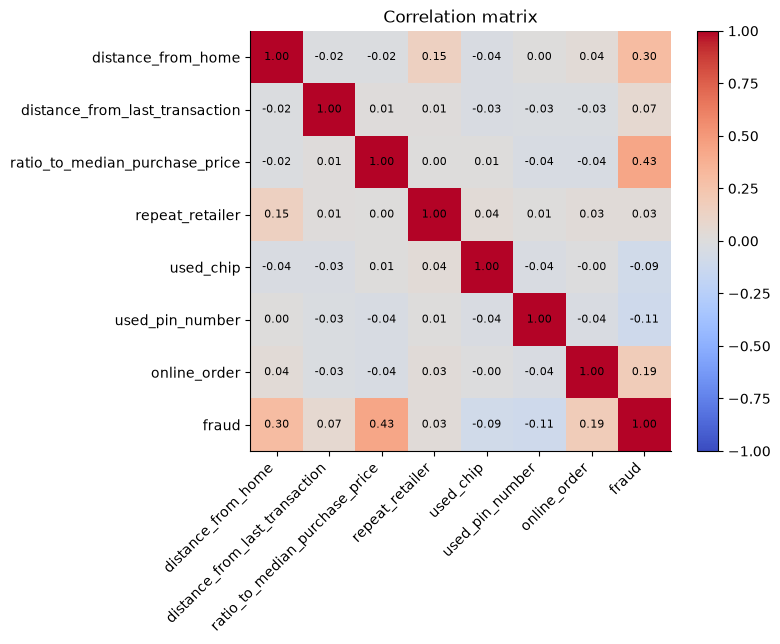

In [23]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

The features are only weakly correlated with each other, so each one adds largely independent information. The strongest correlations with `fraud` match the findings above.

## 4. Modeling

### 4.1 Train/test split (80% / 20%)

The split is **stratified** so the training and test sets both keep the ~8% fraud rate. Without stratification, a random 20% test set could end up with noticeably more or fewer fraud cases by chance.

In [24]:
X = df[feature_cols]
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {len(X_train)} rows, {y_train.sum()} fraud ({y_train.mean():.2%})")
print(f"Test set:     {len(X_test)} rows, {y_test.sum()} fraud ({y_test.mean():.2%})")

Training set: 799 rows, 63 fraud (7.88%)
Test set:     200 rows, 16 fraud (8.00%)


In [25]:
def evaluate(model, X_te, y_te):
    """Return a dict of fraud-detection metrics for a fitted classifier."""
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred),
        "F1 score": f1_score(y_te, pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "Balanced accuracy": balanced_accuracy_score(y_te, pred),
        "MCC": matthews_corrcoef(y_te, pred),
        "ROC-AUC": roc_auc_score(y_te, proba),
        "PR-AUC": average_precision_score(y_te, proba),
    }

def plot_confusion(y_true, y_pred, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    labels = [CLASS_NAMES[0], CLASS_NAMES[1]]
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1], display_labels=labels,
                                            cmap="Blues", ax=axes[0], colorbar=False)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1], display_labels=labels,
                                            cmap="Blues", ax=axes[1], normalize="true",
                                            values_format=".1%", colorbar=False)
    axes[1].set_title("Row-normalized (% of each actual class)")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    print(f"Fraud caught (TP): {tp}   Fraud missed (FN): {fn}")
    print(f"False alarms (FP): {fp}   Correctly cleared (TN): {tn}")

### 4.2 Baseline: "never fraud" model

This model ignores the features and always predicts the most common class, "legitimate". It sets the bar any real model has to beat.

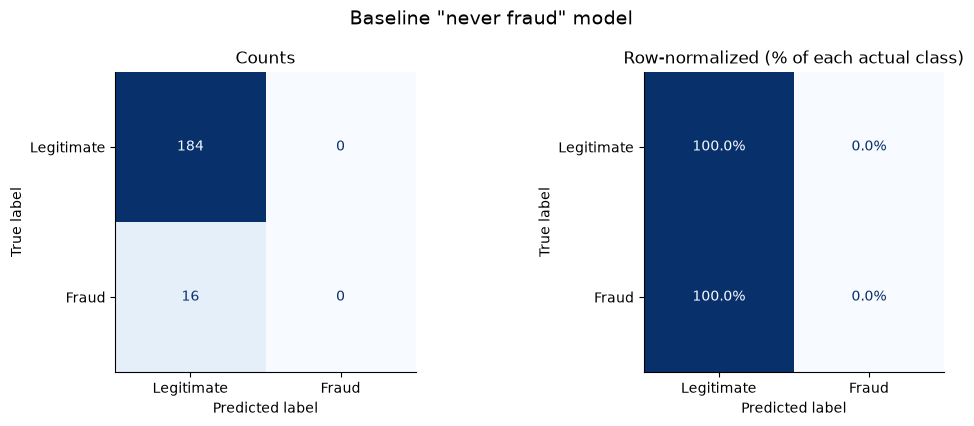

Fraud caught (TP): 0   Fraud missed (FN): 16
False alarms (FP): 0   Correctly cleared (TN): 184


In [26]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

plot_confusion(y_test, y_pred_baseline, 'Baseline "never fraud" model')

The baseline classifies every legitimate transaction correctly, so its accuracy looks high, but it **misses every single fraud case**. In fraud detection that makes it useless, which is why recall, precision and F1 matter more than accuracy here.

### 4.3 KNN model (k = 3)

KNN labels a transaction by looking at the 3 most similar transactions in the training set and taking a majority vote. Because "similar" is measured by distance, the features need some preprocessing first:
1. **Impute** missing values with the median of each column (learned from the training set).
2. **Standardize** every feature to mean 0 and standard deviation 1. Without this, `distance_from_home` (values in the hundreds) would dominate the 0/1 flags.

Both steps are inside a `Pipeline`, so they are fitted on the training data only and then applied to the test data.

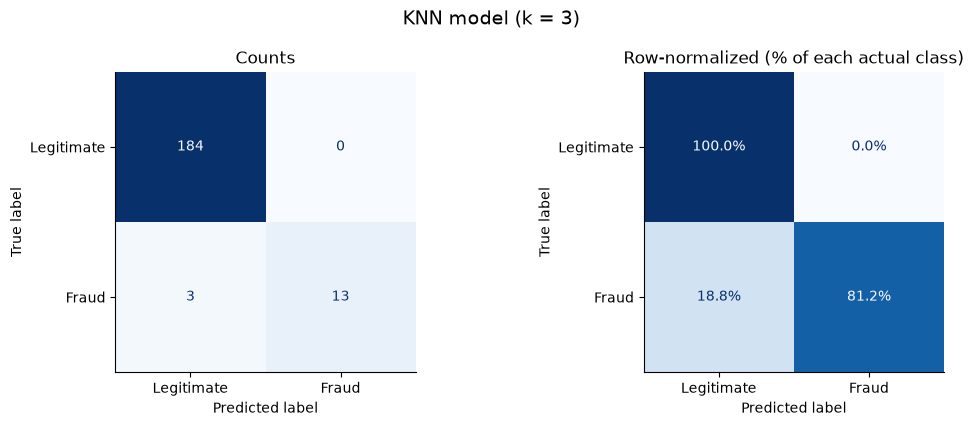

Fraud caught (TP): 13   Fraud missed (FN): 3
False alarms (FP): 0   Correctly cleared (TN): 184


In [27]:
knn = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
])
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

plot_confusion(y_test, y_pred_knn, "KNN model (k = 3)")

In [28]:
print(classification_report(y_test, y_pred_knn, target_names=[CLASS_NAMES[0], CLASS_NAMES[1]], digits=3))

              precision    recall  f1-score   support

  Legitimate      0.984     1.000     0.992       184
       Fraud      1.000     0.812     0.897        16

    accuracy                          0.985       200
   macro avg      0.992     0.906     0.944       200
weighted avg      0.985     0.985     0.984       200



### 4.4 Comparing the two models

Metrics used:

| Metric | What it measures |
|---|---|
| **Accuracy** | Share of all transactions classified correctly (misleading when fraud is rare) |
| **Precision** | Of the transactions flagged as fraud, how many really were fraud |
| **Recall** | Of the actual fraud cases, how many were caught |
| **F1 score** | Balance of precision and recall |
| **Specificity** | Of the legitimate transactions, how many were correctly left alone |
| **Balanced accuracy** | Average of recall and specificity, so both classes count equally |
| **MCC** | Matthews correlation coefficient: one number from -1 to 1 that uses all four confusion-matrix cells and stays honest on imbalanced data (0 = no better than guessing) |
| **ROC-AUC** | How well the model ranks fraud above legitimate transactions (0.5 = random) |
| **PR-AUC** | Area under the precision-recall curve; its random-guess level is the fraud rate (~8%), so it is especially informative for rare-event problems |

In [29]:
comparison = pd.DataFrame({
    'Baseline ("never fraud")': evaluate(baseline, X_test, y_test),
    "KNN (k = 3)": evaluate(knn, X_test, y_test),
})
comparison

,"Baseline (""never fraud"")",KNN (k = 3)
Accuracy,0.920,0.985
Precision,0.000,1.000
Recall,0.000,0.812
F1 score,0.000,0.897
Specificity,1.000,1.000
Balanced accuracy,0.500,0.906
MCC,0.000,0.894
ROC-AUC,0.500,0.998
PR-AUC,0.080,0.963


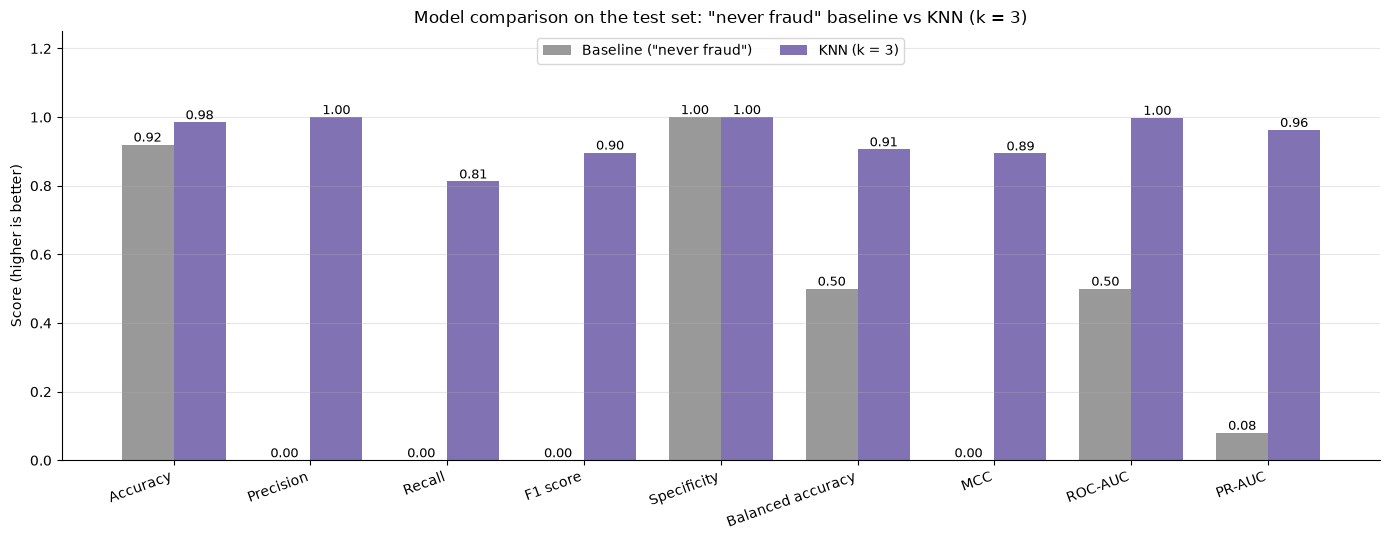

In [30]:
metrics = comparison.index.tolist()
x = np.arange(len(metrics))
w = 0.38

fig, ax = plt.subplots(figsize=(14, 5.5))
for offset, (model_name, color) in zip((-w / 2, w / 2), [(comparison.columns[0], "#999999"),
                                                        (comparison.columns[1], "#8172B3")]):
    vals = comparison[model_name].values
    bars = ax.bar(x + offset, vals, w, color=color, label=model_name)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, max(v, 0), f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, metrics, rotation=20, ha="right")
ax.set_ylim(0, 1.25)
ax.set_ylabel("Score (higher is better)")
ax.set_title('Model comparison on the test set: "never fraud" baseline vs KNN (k = 3)')
ax.legend(loc="upper center", ncol=2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The comparison makes the accuracy trap clear: the baseline's accuracy is high only because 92% of transactions are legitimate. On every metric that rewards actually finding fraud (precision, recall, F1, balanced accuracy, MCC, PR-AUC), the baseline scores zero or the level of random guessing, while KNN scores far higher.

Keep in mind that the test set has only about 16 fraud cases, so catching or missing one fraud moves recall by roughly 6 percentage points. These test scores are a useful guide, but they carry real uncertainty.

## 5. Conclusions

**What distinguishes fraud from legitimate transactions**
- **Purchase size relative to the cardholder's norm** (`ratio_to_median_purchase_price`) is the strongest signal: about 70% of fraudulent purchases fall in the top fifth of this variable (more than about 2.2 times the cardholder's median purchase).
- **Online orders** account for almost all fraud in this data.
- **PIN use** is strongly protective: no transaction that used a PIN was fraudulent. **Chip use** is also associated with less fraud.
- **Distance from home** is higher for fraud, and transactions very far from home are suspicious even when the purchase is normal-sized. Distance from the last transaction and repeat-retailer status add little on their own.

**Model performance**
- The "never fraud" baseline shows why accuracy is misleading for rare events: it is about 92% accurate yet catches no fraud at all.
- The KNN model (k = 3), with median imputation and standardization, catches most of the fraud in the test set while raising few false alarms, and beats the baseline on every fraud-focused metric.

**Possible next steps**
- Try other values of *k* with cross-validation to check whether k = 3 is a good choice.
- Log-transform the skewed distance and price features before scaling, which can help a distance-based model like KNN.
- Compare against other classifiers such as logistic regression or random forests.